# Length of stay: one combined model vs. separate dog and cat models

**Question:** does training a separate model per species beat one model that has `animal_type` as a feature?

The EDA suggests it might. Dogs and cats differ in outcome mix (dogs go back to owners far more often, cats are transferred more), in seasonality (kitten season), and in how age relates to stay length.

**Design (same split, features and metrics as notebooks 01–12):**
- **Combined:** one model trained on all training rows (dogs + cats).
- **Species-specific:** a dog model trained only on dog rows, and a cat model trained only on cat rows. Each animal is predicted by its own species' model.
- Both approaches use the **tuned hyperparameters** from notebooks 02–11 (tuned on the combined data). Section 3 re-tunes gradient boosting per species to check whether that matters.
- Scored on 2022 val, per species and overall. Test is still untouched.

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
import utils

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()
pd.crosstab(train["animal_type"], train["los_bin"], normalize="index")[utils.LOS_BIN_LABELS].round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split


los_bin,<1 week,1-4 weeks,1-3 months,3+ months
animal_type,,,,
Cat,0.509,0.243,0.203,0.045
Dog,0.592,0.275,0.096,0.036


In [2]:
# Base estimators (same as notebooks 01-11) + tuned params saved by each notebook
BASE = {
    "Majority class (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=utils.SEED),
    "Decision tree": DecisionTreeClassifier(random_state=utils.SEED),
    "Random forest": RandomForestClassifier(n_jobs=-1, random_state=utils.SEED),
    "Extra trees": ExtraTreesClassifier(n_jobs=-1, random_state=utils.SEED),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=utils.SEED),
    "AdaBoost": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, random_state=utils.SEED),
                                   random_state=utils.SEED),
    "Gaussian naive Bayes": GaussianNB(),
    "k-nearest neighbors": KNeighborsClassifier(n_jobs=-1),
    "Linear SVM": LinearSVC(random_state=utils.SEED),
    "Neural network (MLP)": utils.SafeMLPClassifier(random_state=utils.SEED),
}

def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

MODELS = {}
for name, est in BASE.items():
    f = RESULTS_DIR / f"{slug(name + ' (tuned)')}.json"
    params = json.loads(f.read_text())["best_params"] if f.exists() else {}
    MODELS[name] = utils.with_params(est, params)
    print(f"{name:28s} {'tuned' if params else 'default'} {params}")

Majority class (baseline)    default {}
Logistic regression          tuned {'C': 3.4702669886504163, 'class_weight': 'balanced'}
Decision tree                tuned {'min_samples_leaf': 100, 'max_depth': 6, 'criterion': 'entropy', 'class_weight': 'balanced'}
Random forest                tuned {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 30, 'class_weight': 'balanced'}
Extra trees                  tuned {'n_estimators': 100, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': None, 'class_weight': 'balanced'}
Gradient boosting            tuned {'class_weight': None, 'l2_regularization': 0.03387255565852149, 'learning_rate': 0.2866812213933528, 'max_iter': 100, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}
AdaBoost                     tuned {'estimator__max_depth': 2, 'learning_rate': 1.6563097558837172, 'n_estimators': 400}
Gaussian naive Bayes         tuned {'var_smoothing': 0.25619560600751484}
k-nearest neighbors          tuned {'weights': 'unifo

## 1. Fit combined and per-species models

In [3]:
def fit_predict(est, tr, ev):
    pipe = Pipeline([("pre", utils.make_preprocessor()), ("model", utils.with_params(est, {}))])
    pipe.fit(tr[utils.FEATURES], tr["los_bin"])
    return pd.Series(pipe.predict(ev[utils.FEATURES]), index=ev.index)

def score(y, p):
    m = utils.classification_metrics(y, p, labels=utils.LOS_BIN_LABELS, verbose=False)
    return {"accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
            "qwk": utils.quadratic_weighted_kappa(y, p, labels=utils.LOS_BIN_LABELS),
            "recall_3+ months": m["recall_3+ months"]}

rows, preds = [], {}
for name, est in MODELS.items():
    p_comb = fit_predict(est, train, val)
    p_spec = pd.concat([fit_predict(est, train[train.animal_type == s], val[val.animal_type == s])
                        for s in ["Dog", "Cat"]]).reindex(val.index)
    preds[name] = (p_comb, p_spec)
    for subset in ["All", "Dog", "Cat"]:
        idx = val.index if subset == "All" else val.index[val.animal_type == subset]
        for approach, p in [("combined", p_comb), ("species-specific", p_spec)]:
            rows.append({"model": name, "subset": subset, "approach": approach,
                         **score(val.loc[idx, "los_bin"], p.loc[idx])})
    print(f"done: {name}", flush=True)

species = pd.DataFrame(rows)
species.to_csv(RESULTS_DIR / "species_split.csv", index=False)

done: Majority class (baseline)


done: Logistic regression


done: Decision tree


done: Random forest


done: Extra trees


done: Gradient boosting


... (4 outputs left out)

/opt/homebrew/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/opt/homebrew/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


/opt/homebrew/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


done: Neural network (MLP)


## 2. Does splitting by species help?

`delta` = species-specific − combined. Positive means the separate models are better.

In [4]:
wide = species.pivot_table(index=["model", "subset"], columns="approach",
                           values=["accuracy", "macro_f1", "qwk"])
delta = pd.DataFrame({m: wide[(m, "species-specific")] - wide[(m, "combined")]
                      for m in ["accuracy", "macro_f1", "qwk"]})
summary = pd.concat({"combined": wide.xs("combined", axis=1, level=1),
                     "species-specific": wide.xs("species-specific", axis=1, level=1),
                     "delta": delta}, axis=1)
summary.loc[(slice(None), "All"), :].droplevel(1).sort_values(("combined", "macro_f1"), ascending=False) \
    .style.format("{:.3f}").background_gradient(cmap="RdYlGn", subset=[("delta", c) for c in ["accuracy", "macro_f1", "qwk"]], vmin=-.03, vmax=.03)

In [5]:
# Per species: where does a separate model help or hurt?
summary.loc[(slice(None), ["Dog", "Cat"]), :].style.format("{:.3f}") \
    .background_gradient(cmap="RdYlGn", subset=[("delta", c) for c in ["accuracy", "macro_f1", "qwk"]], vmin=-.03, vmax=.03)

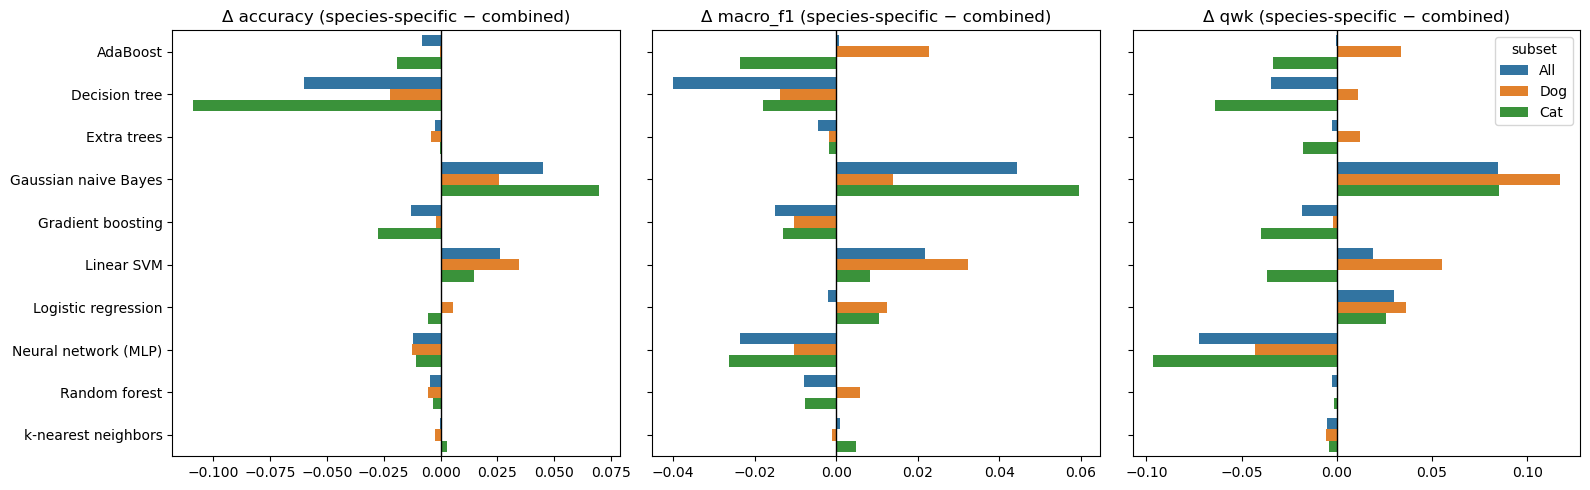

In [6]:
plot = delta.reset_index()
plot = plot[plot["model"] != "Majority class (baseline)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, m in zip(axes, ["accuracy", "macro_f1", "qwk"]):
    sns.barplot(data=plot, y="model", x=m, hue="subset", ax=ax, hue_order=["All", "Dog", "Cat"])
    ax.axvline(0, color="k", lw=1)
    ax.set_title(f"Δ {m} (species-specific − combined)"); ax.set_xlabel(""); ax.set_ylabel("")
    if m != "qwk":
        ax.get_legend().remove()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "species_split_delta.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Re-tuning gradient boosting per species

The species-specific models above reuse settings tuned on the combined data. Smaller, more uniform datasets may prefer different settings. As a check, gradient boosting is re-tuned on dogs only and on cats only, using the same inner-split procedure.

In [7]:
retuned = {}
for s in ["Dog", "Cat"]:
    tr_s = train[train.animal_type == s]
    best_s, res_s, info_s = utils.tune_classifier(BASE["Gradient boosting"], {
        "learning_rate": loguniform(0.02, 0.3),
        "max_iter": [100, 200, 400],
        "max_leaf_nodes": [15, 31, 63, 127],
        "min_samples_leaf": [20, 50, 100, 200],
        "l2_regularization": loguniform(1e-3, 10),
        "class_weight": [None, "balanced"],
    }, tr_s, name=f"Gradient boosting {s} (tuned)", n_iter=20, results_dir=RESULTS_DIR)
    retuned[s] = fit_predict(utils.with_params(BASE["Gradient boosting"], best_s), tr_s, val[val.animal_type == s])

p_comb, p_spec = preds["Gradient boosting"]
p_retuned = pd.concat(retuned.values()).reindex(val.index)
gb = []
for subset in ["All", "Dog", "Cat"]:
    idx = val.index if subset == "All" else val.index[val.animal_type == subset]
    for approach, p in [("combined (tuned on all)", p_comb), ("species-specific, combined params", p_spec),
                        ("species-specific, re-tuned per species", p_retuned)]:
        gb.append({"subset": subset, "approach": approach, **score(val.loc[idx, "los_bin"], p.loc[idx])})
pd.DataFrame(gb).set_index(["subset", "approach"]).round(3)

time_group_split: dropped 477 rows (0.6%) belonging to animals first seen in an earlier split


Gradient boosting Dog (tuned): 20 candidates in 3.0 min | sub-train 69,405, inner-val 5,699 | best inner-val f1_macro 0.380
best params: {'class_weight': None, 'l2_regularization': 0.0019777828512462727, 'learning_rate': 0.0527981135485379, 'max_iter': 100, 'max_leaf_nodes': 127, 'min_samples_leaf': 100}


time_group_split: dropped 115 rows (0.2%) belonging to animals first seen in an earlier split


/opt/homebrew/anaconda3/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Gradient boosting Cat (tuned): 20 candidates in 1.4 min | sub-train 46,074, inner-val 4,988 | best inner-val f1_macro 0.365
best params: {'class_weight': None, 'l2_regularization': 0.0019777828512462727, 'learning_rate': 0.0527981135485379, 'max_iter': 100, 'max_leaf_nodes': 127, 'min_samples_leaf': 100}


accuracy  macro_f1    qwk  \
subset approach                                                            
All    combined (tuned on all)                    0.517     0.383  0.314   
       species-specific, combined params          0.504     0.368  0.295   
       species-specific, re-tuned per species     0.515     0.363  0.298   
Dog    combined (tuned on all)                    0.524     0.364  0.311   
       species-specific, combined params          0.523     0.354  0.309   
       species-specific, re-tuned per species     0.522     0.345  0.295   
Cat    combined (tuned on all)                    0.506     0.372  0.304   
       species-specific, combined params          0.479     0.359  0.264   
       species-specific, re-tuned per species     0.506     0.367  0.289   

                                               recall_3+ months  
subset approach                                                  
All    combined (tuned on all)                            0.074  
       species-specific, combined params                  0.054  
       species-specific, re-tuned per species             0.018  
Dog    combined (tuned on all)                            0.111  
       species-specific, combined params                  0.072  
       species-specific, re-tuned per species             0.028  
Cat    combined (tuned on all)                            0.005  
       species-specific, combined params                  0.021  
       species-specific, re-tuned per species             0.000

## Takeaways

_Filled in after running._